<a href="https://colab.research.google.com/github/peigemitchell-svg/Google-Colab/blob/main/Research_Paper_Python_Data_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#Install Python Libraries
!pip install -q pandas "dask[dataframe]"

In [3]:
#Upload the inventory dataset

from google.colab import files

uploaded = files.upload()

#Confirm the file was uploaded.
import os

csv_path = "inventory.csv"

if os.path.exists(csv_path):
    print("CSV uploaded successfully:", csv_path)
else:
    raise FileNotFoundError(
        "Please upload the file named inventory.csv"
    )

Saving inventory.csv to inventory.csv
CSV uploaded successfully: inventory.csv


In [4]:
#Import libraries and configure logging

import logging
from pathlib import Path

import pandas as pd
import dask.dataframe as dd

logging.basicConfig(
    filename="etl.log",
    level=logging.INFO,
    format="%(asctime)s %(levelname)s %(message)s",
    force=True
)

REQUIRED = [
    "server",
    "path",
    "size_bytes",
    "modified"
]

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
#Create data cleaning

def clean_chunk(chunk):
    chunk = chunk.copy()

    chunk["size_bytes"] = pd.to_numeric(
        chunk["size_bytes"],
        errors="coerce"
    )

    chunk["modified"] = pd.to_datetime(
        chunk["modified"],
        errors="coerce",
        utc=True
    )

    good = (
        chunk["server"].notna()
        & chunk["path"].notna()
        & chunk["size_bytes"].ge(0)
        & chunk["modified"].notna()
    )

    accepted = chunk.loc[good].copy()
    rejected = chunk.loc[~good].copy()

    return accepted, rejected

print("Data cleaning function ready.")


Data cleaning function ready.


In [7]:
#Process the dataset using pandas chunking
def process_chunks(csv_path, chunk_size=10):
    valid_chunks = []
    rejected_chunks = []

    for chunk_number, chunk in enumerate(
        pd.read_csv(csv_path, chunksize=chunk_size),
        start=1
    ):
        accepted, rejected = clean_chunk(
            chunk[REQUIRED]
        )

        valid_chunks.append(accepted)
        rejected_chunks.append(rejected)

        logging.info(
            "Chunk %s accepted=%s rejected=%s",
            chunk_number,
            len(accepted),
            len(rejected)
        )

        print(
            f"Chunk {chunk_number}: "
            f"Accepted={len(accepted)}, "
            f"Rejected={len(rejected)}"
        )

    clean = pd.concat(
        valid_chunks,
        ignore_index=True
    )

    rejected = pd.concat(
        rejected_chunks,
        ignore_index=True
    )

    before_dedup = len(clean)

    clean = clean.drop_duplicates(
        subset=["server", "path"]
    ).reset_index(drop=True)

    duplicate_count = before_dedup - len(clean)

    logging.info(
        "Final rows=%s rejected=%s duplicates=%s",
        len(clean),
        len(rejected),
        duplicate_count
    )

    print("\nETL Processing Summary")
    print("Valid unique records:", len(clean))
    print("Rejected records:", len(rejected))
    print("Duplicates removed:", duplicate_count)

    return clean, rejected


In [8]:
#Execute ETL Pipeline
cleaned, rejected = process_chunks(
    "inventory.csv",
    chunk_size=10
)

cleaned.to_csv(
    "inventory_curated.csv",
    index=False
)

rejected.to_csv(
    "inventory_rejected.csv",
    index=False
)

print("\nCurated dataset preview:")
display(cleaned.head(10))


Chunk 1: Accepted=10, Rejected=0
Chunk 2: Accepted=10, Rejected=0
Chunk 3: Accepted=10, Rejected=0
Chunk 4: Accepted=10, Rejected=0
Chunk 5: Accepted=10, Rejected=0
Chunk 6: Accepted=10, Rejected=0
Chunk 7: Accepted=3, Rejected=5

ETL Processing Summary
Valid unique records: 60
Rejected records: 5
Duplicates removed: 3

Curated dataset preview:


,server,path,size_bytes,modified
0,USAFE-FS01,/shares/operations/file_001.dat,1048576.0,2026-02-02 10:30:00+00:00
1,USAFE-FS02,/shares/operations/file_002.dat,2097152.0,2026-03-03 10:30:00+00:00
2,USAFE-NAS01,/shares/operations/file_003.dat,3145728.0,2026-04-04 10:30:00+00:00
3,USAFE-ARCHIVE01,/shares/archive/file_004.dat,4194304.0,2026-05-05 10:30:00+00:00
4,USAFE-FS01,/shares/operations/file_005.dat,5242880.0,2026-06-06 10:30:00+00:00
5,USAFE-FS02,/shares/operations/file_006.dat,6291456.0,2026-07-07 10:30:00+00:00
6,USAFE-NAS01,/shares/operations/file_007.dat,7340032.0,2026-08-08 10:30:00+00:00
7,USAFE-ARCHIVE01,/shares/archive/file_008.dat,8388608.0,2026-09-09 10:30:00+00:00
8,USAFE-FS01,/shares/operations/file_009.dat,9437184.0,2026-01-10 10:30:00+00:00
9,USAFE-FS02,/shares/operations/file_010.dat,10485760.0,2026-02-11 10:30:00+00:00


In [9]:
#Analyze the cleaned data using Dask
def dask_summary(csv_path):
    ddf = dd.read_csv(
        csv_path,
        assume_missing=True
    )

    summary = ddf.groupby("server")[
        "size_bytes"
    ].agg(["count", "sum"]).compute()

    return summary

dask_results = dask_summary(
    "inventory_curated.csv"
)

print("Dask Server Storage Summary:")
display(dask_results)


Dask Server Storage Summary:


,count,sum
server,,
USAFE-FS01,15,456130560.0
USAFE-FS02,15,471859200.0
USAFE-NAS01,15,487587840.0
USAFE-ARCHIVE01,15,503316480.0


In [12]:
#Create MapReduce aggregation

def reduce_records(records):
    totals = {}
    for record in records:
        server = record["server"]
        size = record["size_bytes"]

        # Initialize if not present
        if server not in totals:
            totals[server] = (0, 0.0)

        current_count, current_size = totals[server]
        totals[server] = (current_count + 1, current_size + size)

    return totals

mapreduce_results = reduce_records(
    cleaned.to_dict("records")
)

print("MapReduce Aggregation Results:")

for server, (count, size) in mapreduce_results.items():
    print(
        f"{server}: "
        f"{count} files, "
        f"{int(size):,} bytes"
    )

MapReduce Aggregation Results:
USAFE-FS01: 15 files, 456,130,560 bytes
USAFE-FS02: 15 files, 471,859,200 bytes
USAFE-NAS01: 15 files, 487,587,840 bytes
USAFE-ARCHIVE01: 15 files, 503,316,480 bytes


In [13]:
#Compare Dask and MapReduce

for server, (count, size) in mapreduce_results.items():
    dask_count = int(dask_results.loc[server, "count"])
    dask_size = int(dask_results.loc[server, "sum"])

    assert count == dask_count
    assert size == dask_size

print("Validation successful!")
print("Dask and MapReduce results match.")

Validation successful!
Dask and MapReduce results match.


In [15]:
#Dataset Validation

assert set(dask_results.index) == set(mapreduce_results.keys())

for server, (count, size) in mapreduce_results.items():
    assert int(dask_results.loc[server, "count"]) == count
    assert int(dask_results.loc[server, "sum"]) == size

print("Validation successful.")
print("All server counts and storage totals match.")


Validation successful.
All server counts and storage totals match.


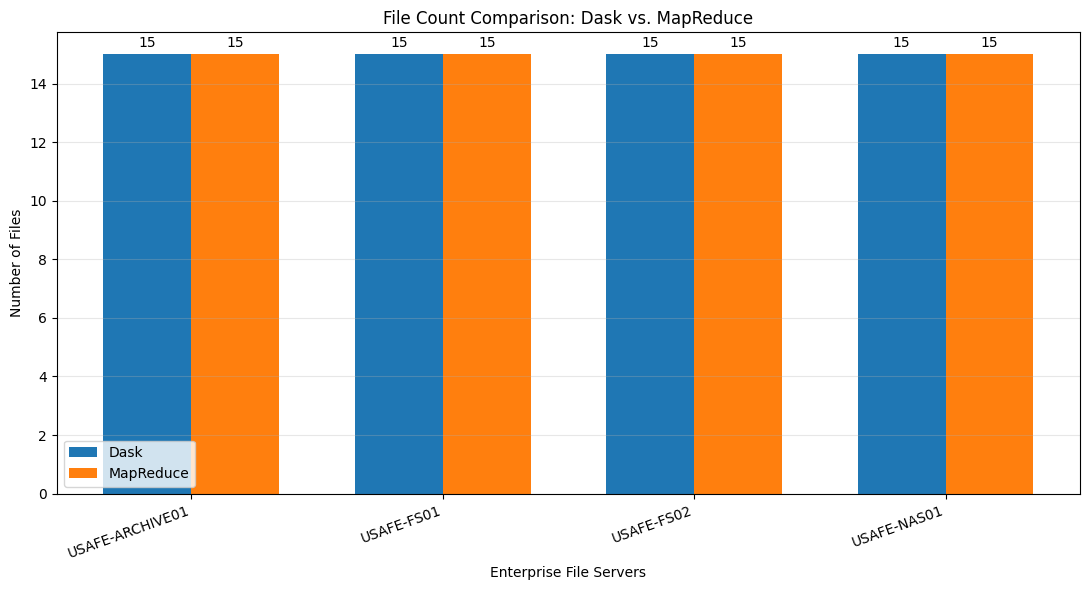

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Convert MapReduce results to a DataFrame
mapreduce_df = pd.DataFrame.from_dict(
    mapreduce_results,
    orient="index",
    columns=["count", "sum"]
)

# Align results by server
comparison = dask_results[["count", "sum"]].join(
    mapreduce_df[["count", "sum"]],
    how="inner",
    lsuffix="_dask",
    rsuffix="_mapreduce"
).sort_index()

# Configure grouped bar chart
x = np.arange(len(comparison))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width / 2,
    comparison["count_dask"],
    width,
    label="Dask"
)

bars2 = ax.bar(
    x + width / 2,
    comparison["count_mapreduce"],
    width,
    label="MapReduce"
)

ax.set_title(
    "File Count Comparison: Dask vs. MapReduce"
)
ax.set_xlabel("Enterprise File Servers")
ax.set_ylabel("Number of Files")
ax.set_xticks(x)
ax.set_xticklabels(
    comparison.index,
    rotation=20,
    ha="right"
)
ax.legend()
ax.grid(axis="y", alpha=0.3)

ax.bar_label(bars1, padding=3)
ax.bar_label(bars2, padding=3)

plt.tight_layout()
plt.savefig("file_count_comparison.png", dpi=300)
plt.show()
